# Hotel Booking Demand Dataset - Exploratory Data Analysis (EDA)

**Name:** Unta Chaitanya Datta

This notebook follows all five phases required in the assignment:
1. Dataset Selection & Problem Definition
2. Data Cleaning & Integrity Checks
3. Outlier Analysis
4. Bivariate & Multivariate Exploration
5. Feature Engineering & Encoding Preparation


## Introduction

### Dataset Source

The Hotel Booking Demand Dataset was obtained from Kaggle. It contains booking information for City Hotels and Resort Hotels, including customer details, stay information, booking channels, and pricing data.


## Data Dictionary

- hotel : Hotel Type
- is_canceled : Booking Cancellation Status
- lead_time : Number of days before arrival when booking was made
- arrival_date_year : Arrival Year
- arrival_date_month : Arrival Month
- stays_in_weekend_nights : Weekend Nights Stayed
- stays_in_week_nights : Weekday Nights Stayed
- adults : Number of Adults
- children : Number of Children
- babies : Number of Babies
- meal : Meal Plan
- country : Customer Country
- market_segment : Booking Segment
- distribution_channel : Distribution Channel
- customer_type : Customer Type
- adr : Average Daily Rate


## Business Questions

1. Which hotel type receives more bookings?
2. Does lead time affect booking cancellations?
3. Which market segment contributes the most bookings?
4. Which hotel type has higher ADR?
5. How do guest counts vary across bookings?


In [28]:
# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

sns.set_style("whitegrid")

print("Libraries imported successfully")


Libraries imported successfully


## Phase 1: Dataset Selection & Problem Definition

**Dataset Source:** Kaggle - Hotel Booking Demand Dataset

In [29]:
# Load Dataset

df = pd.read_csv("/content/hotel_bookings.csv")

print("Dataset loaded successfully")
df.head()


Dataset loaded successfully


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [30]:
# Dataset Shape

print("Rows and Columns:")
print(df.shape)


Rows and Columns:
(119390, 32)


In [31]:
# Dataset Information

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [32]:
# Data Types Verification

df.dtypes


,0
hotel,object
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,object
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


## Phase 2: Data Cleaning & Integrity Checks

In [33]:
# Statistical Summary

df.describe()


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [34]:
# Check Missing Values

df.isnull().sum()


,0
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0


### Missing Value Treatment
Missing values were identified using isnull().sum(). Numerical columns were imputed using their mean values, while categorical columns were imputed using their mode values.

This approach was chosen because dropping rows would result in the loss of valuable information. Mean imputation preserves the overall distribution of numerical data, and mode imputation replaces missing categorical values with the most frequently occurring category.

In [35]:
# Handle Missing Values

num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(exclude=np.number).columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

for col in num_cols:
    df[col] = df[col].fillna(df[col].mean())

print("Remaining Missing Values:", df.isnull().sum().sum())


Remaining Missing Values: 0


In [36]:
# Duplicate Check

print("Duplicate Rows:", df.duplicated().sum())


Duplicate Rows: 32013


In [37]:
# Remove Duplicate Rows

df = df.drop_duplicates()

print("New Shape:", df.shape)


New Shape: (87377, 32)


In [38]:
# Separate Numerical and Categorical Columns

num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(exclude=np.number).columns

print("Numerical Columns")
print(num_cols)

print("\nCategorical Columns")
print(cat_cols)


Numerical Columns
Index(['is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_week_number', 'arrival_date_day_of_month',
       'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children',
       'babies', 'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company',
       'days_in_waiting_list', 'adr', 'required_car_parking_spaces',
       'total_of_special_requests'],
      dtype='object')

Categorical Columns
Index(['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
       'distribution_channel', 'reserved_room_type', 'assigned_room_type',
       'deposit_type', 'customer_type', 'reservation_status',
       'reservation_status_date'],
      dtype='object')


## Phase 3: Outlier Analysis

In [39]:
# Skewness Analysis

df[num_cols].skew()


,0
is_canceled,1.008124
lead_time,1.431544
arrival_date_year,-0.297186
arrival_date_week_number,0.022348
arrival_date_day_of_month,0.000349
stays_in_weekend_nights,1.411530
stays_in_week_nights,2.691262
adults,19.865355
children,3.463197
babies,21.146221


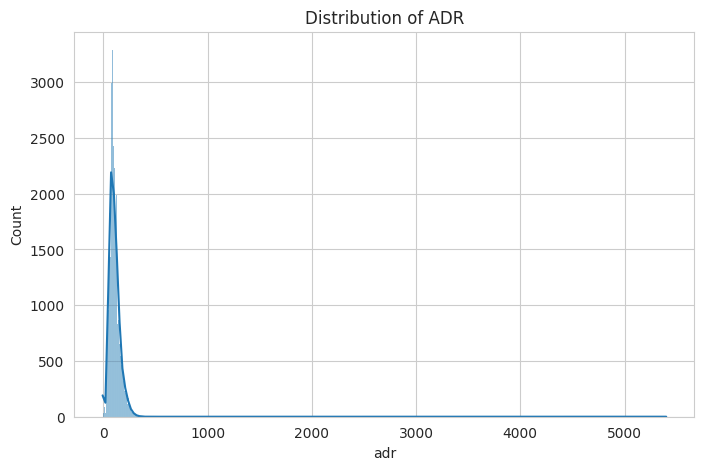

In [40]:
# Histogram of ADR

plt.figure(figsize=(8,5))
sns.histplot(df["adr"], kde=True)
plt.title("Distribution of ADR")
plt.show()


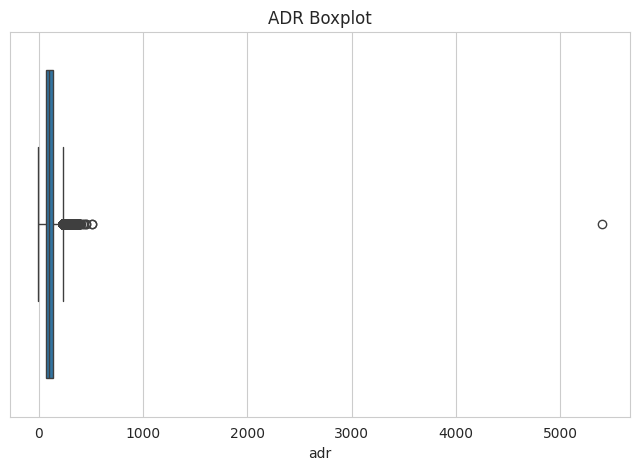

In [41]:
# Boxplot of ADR

plt.figure(figsize=(8,5))
sns.boxplot(x=df["adr"])
plt.title("ADR Boxplot")
plt.show()


In [42]:
# IQR Loop for All Numerical Columns

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, ":", len(outliers))


is_canceled : 0
lead_time : 2396
arrival_date_year : 0
arrival_date_week_number : 0
arrival_date_day_of_month : 0
stays_in_weekend_nights : 220
stays_in_week_nights : 1531
adults : 22887
children : 8368
babies : 914
is_repeated_guest : 3415
previous_cancellations : 1685
previous_bookings_not_canceled : 3545
booking_changes : 15901
agent : 0
company : 5255
days_in_waiting_list : 860
adr : 2488
required_car_parking_spaces : 7313
total_of_special_requests : 2672


In [43]:
# Outlier Treatment for ADR using Winsorization (Capping)

Q1 = df["adr"].quantile(0.25)
Q3 = df["adr"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df["adr"] = np.where(df["adr"] > upper, upper, df["adr"])
df["adr"] = np.where(df["adr"] < lower, lower, df["adr"])

print("ADR Outliers Capped Successfully")


ADR Outliers Capped Successfully


## Phase 4: Bivariate & Multivariate Exploration

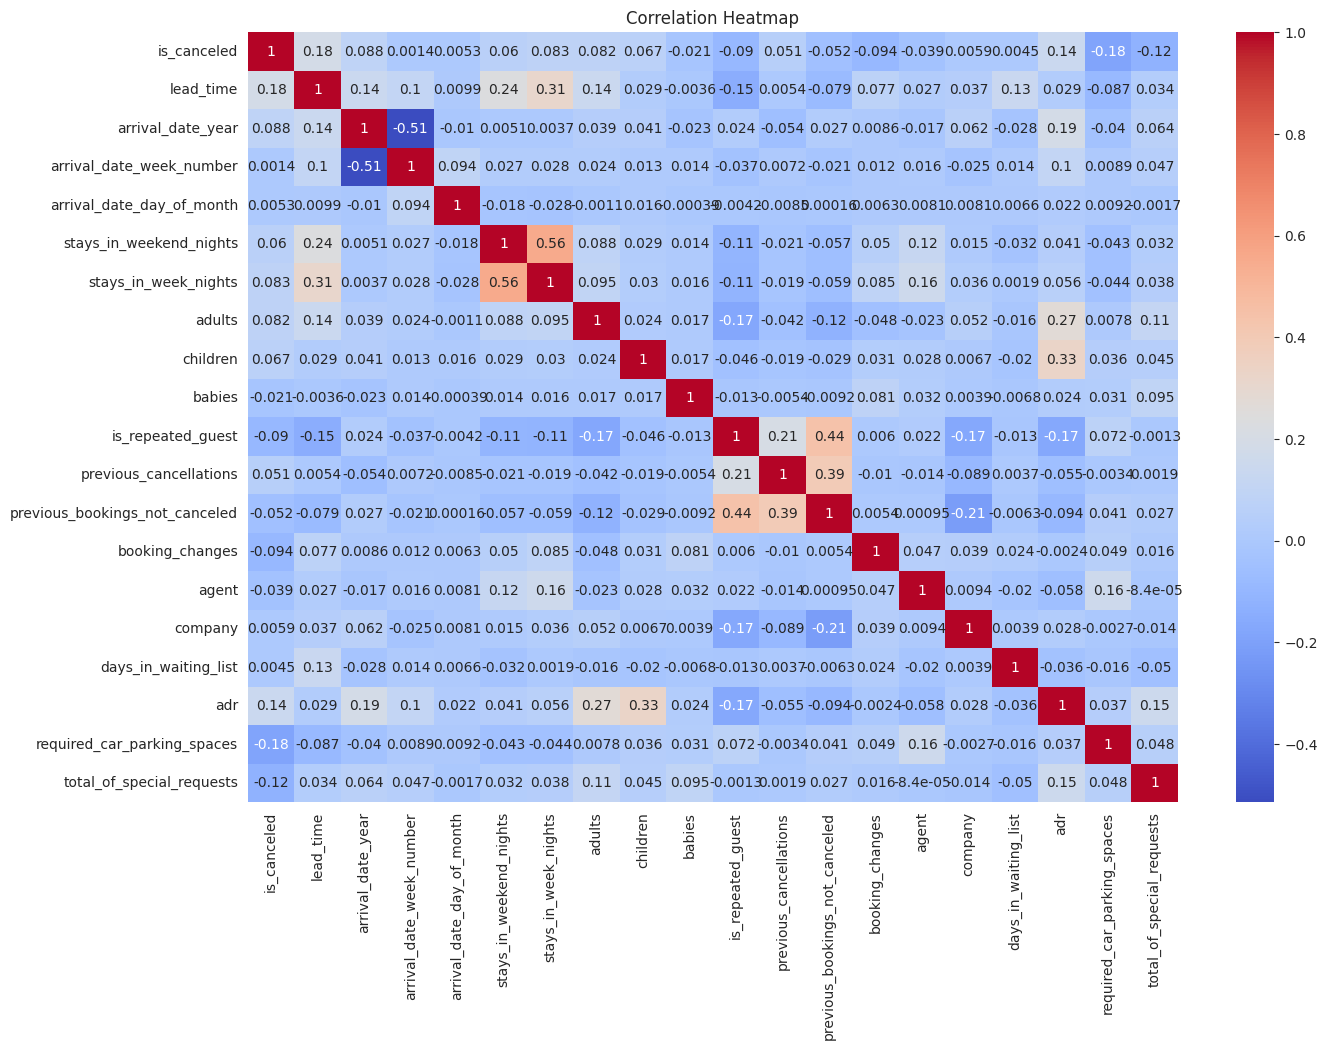

In [44]:
# Correlation Heatmap

plt.figure(figsize=(15,10))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


### Correlation Interpretation

Strong positive correlations indicate variables increase together.
Strong negative correlations indicate one variable decreases as another increases.


### Correlation vs Causation

The correlations observed in this analysis do not necessarily imply direct causation. While some variables may show strong positive or negative relationships, these associations can be influenced by hidden factors such as seasonality, customer preferences, hotel type, booking behavior, or market conditions. Therefore, the results should be interpreted as relationships between variables rather than proof that one variable directly causes changes in another.

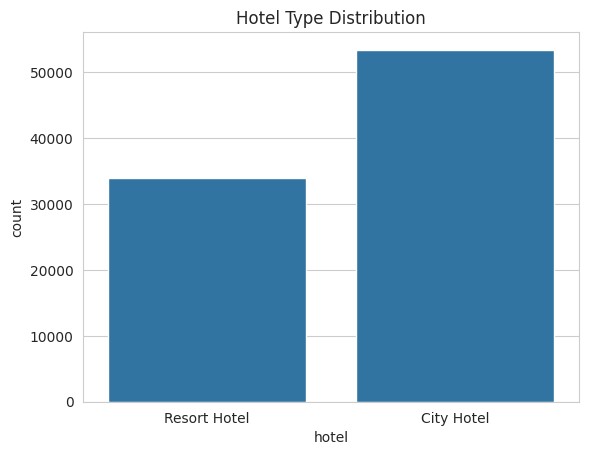

In [45]:
# Hotel Type Distribution

sns.countplot(data=df, x="hotel")
plt.title("Hotel Type Distribution")
plt.show()


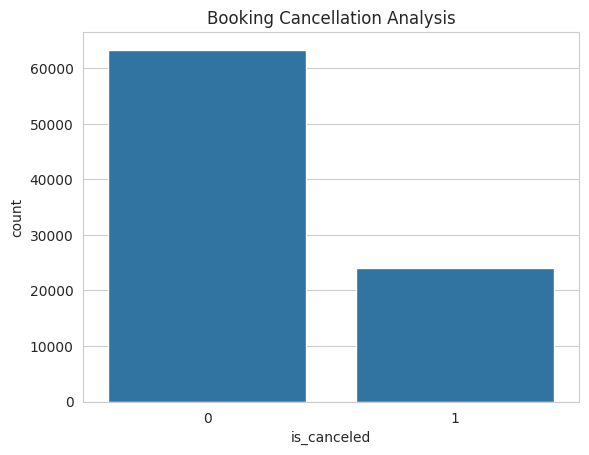

In [46]:
# Booking Cancellation Analysis

sns.countplot(data=df, x="is_canceled")
plt.title("Booking Cancellation Analysis")
plt.show()


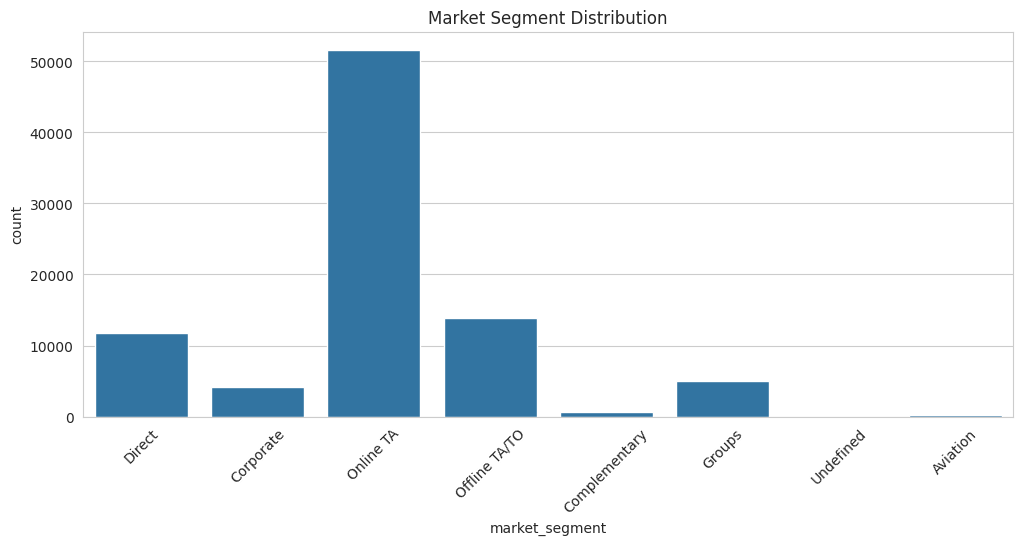

In [47]:
# Market Segment Analysis

plt.figure(figsize=(12,5))
sns.countplot(data=df, x="market_segment")
plt.xticks(rotation=45)
plt.title("Market Segment Distribution")
plt.show()


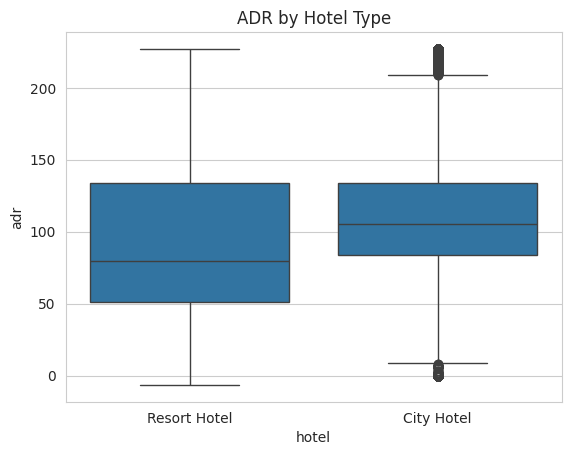

In [52]:
# Bivariate Analysis: Hotel Type vs ADR

sns.boxplot(x="hotel", y="adr", data=df)
plt.title("ADR by Hotel Type")
plt.show()


## Phase 5: Feature Engineering & Encoding Preparation

In [49]:
# Feature Engineering

df["Total_Guests"] = df["adults"] + df["children"] + df["babies"]

df["Total_Nights"] = df["stays_in_week_nights"] + df["stays_in_weekend_nights"]

df[["Total_Guests","Total_Nights"]].head()


,Total_Guests,Total_Nights
0,2.0,0
1,2.0,0
2,1.0,1
3,1.0,1
4,2.0,2


## Ordinal and Nominal Variables

### Ordinal Variables
- meal

### Nominal Variables
- hotel
- country
- market_segment
- distribution_channel
- customer_type
- reserved_room_type


### Encoding Preparation

Label Encoding is applied to ordinal variables.
One-Hot Encoding is applied to nominal variables.


In [50]:
# Label Encoding

le = LabelEncoder()

df["meal"] = le.fit_transform(df["meal"])


In [51]:
# One Hot Encoding

df = pd.get_dummies(
    df,
    columns=["market_segment"],
    drop_first=True
)

df.head()


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,reservation_status_date,Total_Guests,Total_Nights,market_segment_Complementary,market_segment_Corporate,market_segment_Direct,market_segment_Groups,market_segment_Offline TA/TO,market_segment_Online TA,market_segment_Undefined
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,2015-07-01,2.0,0,False,False,True,False,False,False,False
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,2015-07-01,2.0,0,False,False,True,False,False,False,False
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,2015-07-02,1.0,1,False,False,True,False,False,False,False
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,2015-07-02,1.0,1,False,True,False,False,False,False,False
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,2015-07-03,2.0,2,False,False,False,False,False,True,False


## Key Findings

1. City Hotel received more bookings than Resort Hotel.
2. ADR contained outliers and they were treated using capping.
3. Market Segment significantly influenced booking volume.
4. Missing values and duplicate records were successfully handled.
5. Feature engineering created Total Guests and Total Nights.
6. Correlation analysis revealed meaningful relationships among numerical variables.


## Conclusion

Exploratory Data Analysis was successfully performed on the Hotel Booking Demand Dataset.

- Missing values were handled.
- Duplicate rows were removed.
- Outliers were detected using IQR and treated using Winsorization.
- Correlation analysis and visualizations were performed.
- Feature engineering and encoding prepared the data for future machine learning tasks.
